### EDA

Learn Basics About the Dataset





## Setup

In [ ]:
import os                      
import random   
import numpy as np   
import pandas as pd 
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image 

In [ ]:
base_dir = str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists()))  # repo root
img_root = os.path.join(base_dir, "data/ecommons/final_maps/Bax_LiteratureMaps_final_maps")
labels_csv = os.path.join(base_dir, "data/ecommons/Gemini/Bax_LiteratureMaps_Gemini/Gemini_fict-scale_full.csv")
scale_names = {0: "Small (0)", 1: "Medium (1)", 2: "Large (2)"}

In [13]:
labels = pd.read_csv(labels_csv)
 
print("Number of rows in CSV:",len(labels))
print("Columns:", list(labels.columns))
print()
 
# Num of maps in each scale class
scale_counts = labels["Scale"].value_counts().sort_index()
scale_percent = (scale_counts / len(labels) * 100).round(1)
print("Scale class counts:")
print(pd.DataFrame({"count": scale_counts, "percent": scale_percent})) #i find pd dataframes easier to read
print()
 
# Same for fictional vs real
print("Fictionality counts:")
print(labels["Fictionality"].value_counts())
print()


Number of rows in CSV: 2622
Columns: ['Fictionality', 'Explanation_fict', 'Image', 'Scale', 'Explanation_scale']

Scale class counts:
       count  percent
Scale                
0        210      8.0
1        553     21.1
2       1859     70.9

Fictionality counts:
Fictionality
real         1971
fictional     651
Name: count, dtype: int64



In [17]:
labels["full_path"] = img_root + "/" + labels["Image"]
 
# Does file exist
labels["file_exists"] = labels["full_path"].apply(os.path.exists) #src: https://stackoverflow.com/questions/8933237/how-do-i-check-if-a-directory-exists-in-python

#are any missing 
num_missing = (labels["file_exists"] == False).sum()
print("Images listed in CSV: ", len(labels))
print("Missing from folder: ", num_missing)

Images listed in CSV:  2622
Missing from folder:  0


In [19]:
# Full path for every image
image_paths = list(img_root + "/" + labels["Image"])

print("Num images:", len(image_paths))
print("First:", image_paths[0])

Num images: 2622
First: Bax_LiteratureMaps_final_maps/final_maps/000000606028_00000061.jpg


## Resolution

Width: min 883  max 12910  median 1599.5  

Height: min 1201  max 10313  median 2376.0  

Num resolutions: 2459  

['1566 x 2328', '1582 x 2463', '1569 x 2470', '1441 x 2143', '1624 x 2356']


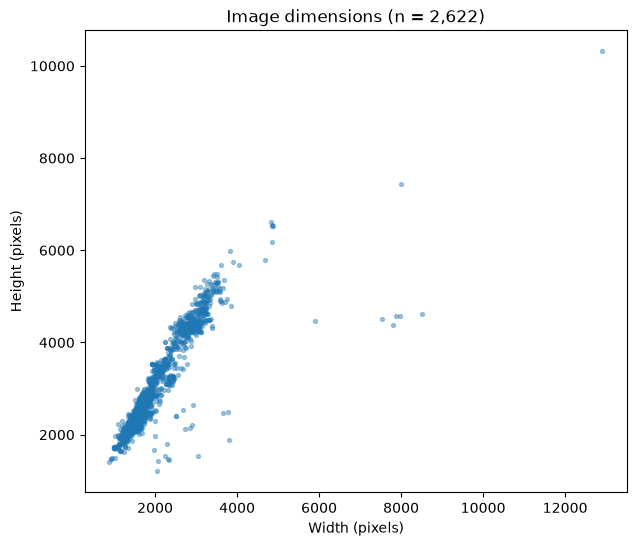

In [29]:
widths = []
heights = []
resolutions = []

for path in image_paths:
    img = Image.open(path) #can use this to "open" the images and see some info about them, but not fully load them, so the code runs faster: https://www.geeksforgeeks.org/python/python-pil-image-open-method/ 
    width = img.size[0]
    height = img.size[1]
    widths.append(width)
    heights.append(height)
    resolutions.append(f"{width} x {height}")

print("Width: min", min(widths), " max", max(widths), " median", np.median(widths),' \n')
print("Height: min", min(heights), " max", max(heights), " median", np.median(heights),' \n')

print("Num resolutions:", len(np.unique(resolutions)),' \n') #taking 
# make sure the resolutions look reasonable
print(resolutions[0:5])

#PLOT
plt.figure(figsize=(7, 6))
plt.scatter(widths, heights, s=8, alpha=0.4)
plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")
plt.title("Image dimensions (n = 2,622)")
plt.show()


## Channels

In [27]:
num_channels = []
formats = []

for path in image_paths:
    img = Image.open(path) #can use this to "open" the images and see some info about them, but not fully load them, so the code runs faster: https://www.geeksforgeeks.org/python/python-pil-image-open-method/ 
    formats.append(img.mode) # "L" = grayscale, "RGB" = color
    channels = img.getbands()
    num_channels.append(len(channels))

#Convert to pd df so I can do calculations easily
num_channels = pd.Series(num_channels)
formats = pd.Series(formats)

print(num_channels.value_counts())
print(formats.value_counts())

3    2622
Name: count, dtype: int64
RGB    2622
Name: count, dtype: int64


/Users/cierrajagan/opt/anaconda3/envs/ml_env/lib/python3.11/site-packages/PIL/Image.py:3578: DecompressionBombWarning: Image size (133140830 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
